# Notebook de documentacion del datasey y tratamiento datos.


## Equipo

- Alumno 1 : Norberto Narvaez
- Alumno 2 :


In [1]:
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

splits = pd.read_csv("data/splits.csv")
print(splits["split"].value_counts())
print("PyTorch:", torch.__version__, "| ¿GPU?:", torch.cuda.is_available())

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


split
train          9581
test_open      3105
test_closed    1986
val            1978
Name: count, dtype: int64
PyTorch: 2.11.0+cu130 | ¿GPU?: False


el Dataset y los DataLoaders


In [2]:
personas_train = sorted(splits.loc[splits["split"] == "train", "identidad"].unique())
clase_de = {nombre: i for i, nombre in enumerate(personas_train)}

aug_train = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(rotate=(-10, 10), translate_percent=(-0.05, 0.05), scale=(0.95, 1.05), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HueSaturationValue(hue_shift_limit=5, sat_shift_limit=15, val_shift_limit=10, p=0.3),
    A.GaussianBlur(blur_limit=(3, 5), p=0.2),
    A.GaussNoise(std_range=(0.02, 0.06), p=0.2),
    A.CoarseDropout(num_holes_range=(1, 2), hole_height_range=(0.1, 0.25), hole_width_range=(0.1, 0.25), p=0.3),
    A.ImageCompression(quality_range=(50, 95), p=0.3),
], seed=SEED)


class CarasDataset(Dataset):
    def __init__(self, tabla, augmentacion=None):
        self.rutas = tabla["path_alineada"].tolist()
        self.etiquetas = [clase_de.get(n, -1) for n in tabla["identidad"]]
        self.augmentacion = augmentacion

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.rutas[i]), cv2.COLOR_BGR2RGB)
        if self.augmentacion is not None:
            img = self.augmentacion(image=img)["image"]
        img = (img.astype(np.float32) - 127.5) / 127.5
        img = torch.from_numpy(img).permute(2, 0, 1)
        return img, self.etiquetas[i]


train_ds = CarasDataset(splits[splits["split"] == "train"], aug_train)
val_ds = CarasDataset(splits[splits["split"] == "val"])

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=0)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=0)

x, y = next(iter(train_dl))
print("Lote de imágenes:", x.shape)
print("Etiquetas:", y[:10])
print("Clases:", len(personas_train))

Lote de imágenes: torch.Size([64, 3, 112, 112])
Etiquetas: tensor([31, 62, 51, 48, 73, 78,  0, 20, 76, 83])
Clases: 85


In [3]:
def bloque(entrada, salida):
    return nn.Sequential(
        nn.Conv2d(entrada, salida, kernel_size=3, padding=1),
        nn.BatchNorm2d(salida),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


class CNNCaras(nn.Module):
    def __init__(self, n_clases, dim_emb=128):
        super().__init__()
        self.features = nn.Sequential(
            bloque(3, 32),
            bloque(32, 64),
            bloque(64, 128),
            bloque(128, 256),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.embedding = nn.Linear(256, dim_emb)
        self.dropout = nn.Dropout(0.3)
        self.clasificador = nn.Linear(dim_emb, n_clases)

    def obtener_embedding(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.embedding(x)

    def forward(self, x):
        emb = self.obtener_embedding(x)
        return self.clasificador(self.dropout(emb))


modelo = CNNCaras(n_clases=len(personas_train))
print(modelo)
print("Parámetros:", sum(p.numel() for p in modelo.parameters()))
print("Salida para un lote:", modelo(x).shape)

CNNCaras(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3

In [7]:
import time
import copy

EPOCAS = 30
PACIENCIA = 5
LR = 1e-3
MODELO_FINAL = Path("models/cnn_caras_final.pth")

criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=2)


def correr_epoca(dl, entrenar):
    modelo.train(entrenar)
    total_loss, aciertos, total = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for x, y in dl:
            salida = modelo(x)
            loss = criterio(salida, y)
            if entrenar:
                optimizador.zero_grad()
                loss.backward()
                optimizador.step()
            total_loss += loss.item() * len(y)
            aciertos += (salida.argmax(1) == y).sum().item()
            total += len(y)
    return total_loss / total, aciertos / total


if MODELO_FINAL.exists():
    modelo.load_state_dict(torch.load(MODELO_FINAL))
    historial = pd.read_csv("data/historial_cnn.csv").to_dict("list")
    print("Modelo cargado desde", MODELO_FINAL)
    print(pd.DataFrame(historial).round(3))
else:
    historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    mejor_val_loss = float("inf")
    epocas_sin_mejora = 0

    for epoca in range(1, EPOCAS + 1):
        inicio = time.time()
        tr_loss, tr_acc = correr_epoca(train_dl, entrenar=True)
        va_loss, va_acc = correr_epoca(val_dl, entrenar=False)
        scheduler.step(va_loss)

        historial["train_loss"].append(tr_loss)
        historial["val_loss"].append(va_loss)
        historial["train_acc"].append(tr_acc)
        historial["val_acc"].append(va_acc)
        pd.DataFrame(historial).to_csv("data/historial_cnn.csv", index=False)

        print(f"Época {epoca:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.3f} | {time.time() - inicio:.0f} s")

        if va_loss < mejor_val_loss:
            mejor_val_loss = va_loss
            mejor_estado = copy.deepcopy(modelo.state_dict())
            torch.save(mejor_estado, "models/cnn_caras_mejor.pth")
            epocas_sin_mejora = 0
        else:
            epocas_sin_mejora += 1
            if epocas_sin_mejora >= PACIENCIA:
                print("Early stopping: la validación no mejoró en", PACIENCIA, "épocas")
                break

    modelo.load_state_dict(mejor_estado)
    torch.save(modelo.state_dict(), MODELO_FINAL)

Modelo cargado desde models/cnn_caras_final.pth
    train_loss  val_loss  train_acc  val_acc
0        4.393     4.257      0.027    0.033
1        4.241     4.195      0.041    0.043
2        4.083     4.085      0.055    0.051
3        3.904     3.942      0.071    0.070
4        3.715     3.522      0.096    0.124
5        3.538     3.747      0.115    0.122
6        3.359     3.249      0.152    0.166
7        3.217     3.224      0.173    0.181
8        3.071     3.238      0.206    0.184
9        2.912     3.200      0.230    0.202
10       2.764     2.578      0.273    0.294
11       2.651     2.641      0.288    0.297
12       2.520     2.844      0.326    0.277
13       2.407     2.516      0.344    0.318
14       2.299     2.473      0.367    0.331
15       2.209     2.340      0.394    0.358
16       2.143     2.301      0.410    0.375
17       2.023     2.031      0.439    0.449
18       1.919     2.104      0.463    0.418
19       1.884     2.259      0.479    0.400
20     

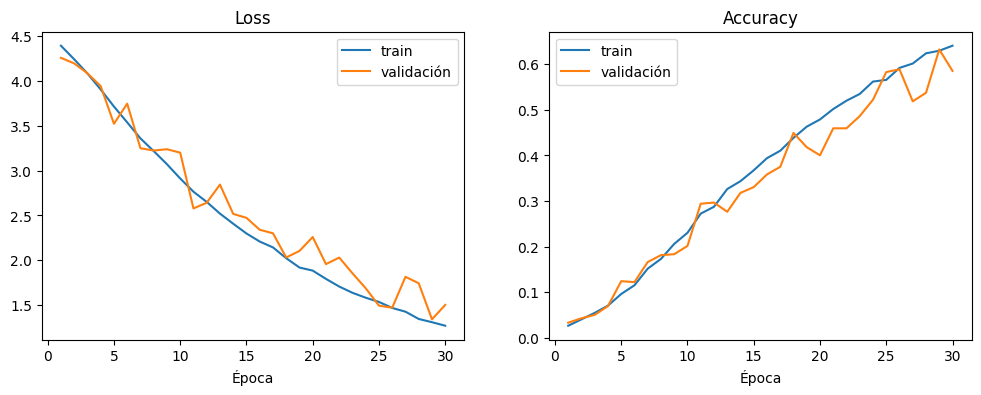

In [8]:
epocas = range(1, len(historial["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epocas, historial["train_loss"], label="train")
axes[0].plot(epocas, historial["val_loss"], label="validación")
axes[0].set_title("Loss")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(epocas, historial["train_acc"], label="train")
axes[1].plot(epocas, historial["val_acc"], label="validación")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Época")
axes[1].legend()

plt.show()

### Arquitectura e hiperparámetros

La CNN tiene 4 bloques convolucionales (convolución 3×3, BatchNorm, ReLU y MaxPool). Los canales se duplican en cada bloque (32, 64, 128 y 256) mientras la imagen se reduce a la mitad, de 112×112 a 7×7. Después usamos global average pooling, una capa lineal que genera el embedding de 128 valores, Dropout de 0,3 y el clasificador de 85 clases. En total tiene 433.237 parámetros y pesa 1,7 MB.

- **BatchNorm** para que el entrenamiento sea más estable.
- **Global average pooling** en vez de aplanar, porque reduce mucho la cantidad de parámetros (256 en lugar de 12.544 valores) y con eso el riesgo de overfitting.
- **Dropout** sobre el embedding, para que la red no dependa de unos pocos valores.

Entrenamos con el enfoque de clasificación + embedding: la red aprende a clasificar a las 85 personas de train y después usamos la capa anterior al clasificador como embedding, normalizado (L2).

| Hiperparámetro        | Valor                                                                                 |
| --------------------- | ------------------------------------------------------------------------------------- |
| Optimizador           | Adam (weight decay 1e-4)                                                              |
| Learning rate inicial | 0,001                                                                                 |
| Scheduler             | ReduceLROnPlateau (divide el LR por 2 si la loss de validación no mejora en 2 épocas) |
| Batch size            | 64                                                                                    |
| Épocas                | 30 como máximo, con early stopping (paciencia 5)                                      |
| Loss                  | Cross-entropy                                                                         |
| Entrada               | Caras alineadas de 112×112, normalizadas a [−1, 1] igual que ArcFace                  |

### Curvas de entrenamiento

Las curvas de train y validación van muy juntas durante todo el entrenamiento, así que no hay overfitting. Lo que se ve es lo contrario: en la época 30 las dos siguen bajando, o sea que el modelo todavía no terminó de aprender (underfitting). Por eso el early stopping nunca se activó. El mejor resultado en validación fue en la época 29, con un accuracy del 63%.

La validación es más irregular que train porque es un conjunto más chico. En algunas épocas su accuracy incluso supera al de train, porque en train la red trabaja con augmentation y dropout, que hacen la tarea más difícil.

Cada época tardó entre 4 y 7 minutos en CPU, así que el entrenamiento completo llevó unas 2,5 horas. Esto limitó la cantidad de experimentos que pudimos hacer.

### Experimentos

| #   | Configuración                                                                 | Resultado                    | Conclusión                                                                            |
| --- | ----------------------------------------------------------------------------- | ---------------------------- | ------------------------------------------------------------------------------------- |
| 1   | 4 bloques conv, embedding 128, Adam lr=1e-3, 30 épocas, augmentation completa | Mejor val acc 63% (época 29) | Sin overfitting, pero sin converger. Con más épocas probablemente seguiría mejorando. |


Como modelo preentrenado usamos el reconocedor **ArcFace** del paquete `buffalo_l` de InsightFace (`w600k_r50.onnx`). Es una ResNet-50 entrenada con la loss ArcFace sobre WebFace600K, un dataset de unas 600 mil identidades. Recibe caras alineadas de 112×112 (con el mismo detector SCRFD y la misma alineación que usamos nosotros) y devuelve un embedding de 512 valores. Tiene unos 43 millones de parámetros y pesa 174 MB.

Lo usamos tal cual, sin reentrenarlo, como extractor de embeddings. Los embeddings ya los calculamos en la Parte 1 para el clustering, así que los reutilizamos.

**Licencia:** los modelos preentrenados de InsightFace solo se pueden usar para investigación o fines no comerciales.


In [9]:
eval_df = splits[splits["split"] != "train"].reset_index(drop=True)

datos = np.load("data/embeddings_arcface.npz")
pos = {p: i for i, p in enumerate(datos["paths"])}
emb_arc = datos["emb"][[pos[p] for p in eval_df["path_alineada"]]]

eval_dl = DataLoader(CarasDataset(eval_df), batch_size=64, shuffle=False, num_workers=0)
modelo.eval()
lotes = []
with torch.no_grad():
    for x, _ in eval_dl:
        lotes.append(modelo.obtener_embedding(x).numpy())
emb_cnn = np.vstack(lotes)
emb_cnn = emb_cnn / np.linalg.norm(emb_cnn, axis=1, keepdims=True)

print("Caras a evaluar:", len(eval_df))
print("Embeddings CNN:", emb_cnn.shape)
print("Embeddings ArcFace:", emb_arc.shape)

Caras a evaluar: 7069
Embeddings CNN: (7069, 128)
Embeddings ArcFace: (7069, 512)


In [10]:
from sklearn.metrics import roc_curve, roc_auc_score

rng = np.random.default_rng(SEED)


def generar_pares(tabla, n_pares):
    fotos_de = {p: np.array(idx) for p, idx in tabla.groupby("identidad").groups.items()}
    personas = list(fotos_de.keys())
    pares, misma_persona = [], []
    for _ in range(n_pares):
        p = rng.choice(personas)
        a, b = rng.choice(fotos_de[p], size=2, replace=False)
        pares.append((a, b))
        misma_persona.append(1)

        p1, p2 = rng.choice(personas, size=2, replace=False)
        pares.append((rng.choice(fotos_de[p1]), rng.choice(fotos_de[p2])))
        misma_persona.append(0)
    return np.array(pares), np.array(misma_persona)


def metricas_verificacion(emb, pares, misma_persona):
    sims = (emb[pares[:, 0]] * emb[pares[:, 1]]).sum(axis=1)
    fpr, tpr, _ = roc_curve(misma_persona, sims)
    auc = roc_auc_score(misma_persona, sims)
    i = np.argmin(np.abs(fpr - (1 - tpr)))
    eer = (fpr[i] + (1 - tpr[i])) / 2
    tar_1e2 = tpr[fpr <= 1e-2].max()
    tar_1e3 = tpr[fpr <= 1e-3].max()
    return sims, fpr, tpr, auc, eer, tar_1e2, tar_1e3


test_open = eval_df[eval_df["split"] == "test_open"]
pares, misma_persona = generar_pares(test_open, 5000)

res_cnn = metricas_verificacion(emb_cnn, pares, misma_persona)
res_arc = metricas_verificacion(emb_arc, pares, misma_persona)

tabla_verif = pd.DataFrame({
    "CNN propia": res_cnn[3:],
    "ArcFace": res_arc[3:],
}, index=["AUC", "EER", "TAR @ FAR=1e-2", "TAR @ FAR=1e-3"]).round(3)
tabla_verif

,CNN propia,ArcFace
AUC,0.850,1.000
EER,0.236,0.002
TAR @ FAR=1e-2,0.162,1.000
TAR @ FAR=1e-3,0.051,0.997


Para la verificación usamos `test_open`, con las 20 personas que ninguno de los dos modelos vio al entrenar. Armamos 5.000 pares de la misma persona y 5.000 de personas distintas, calculamos la similitud coseno de cada par y con eso las métricas.

| Métrica        | CNN propia | ArcFace |
| -------------- | ---------- | ------- |
| AUC            | 0,850      | 1,000   |
| EER            | 0,236      | 0,002   |
| TAR @ FAR=1e-2 | 0,162      | 1,000   |
| TAR @ FAR=1e-3 | 0,051      | 0,997   |

La CNN logra separar a las personas bastante mejor que el azar (AUC 0,85) aunque nunca las vio, lo que muestra que el embedding aprendió algo que generaliza. Pero el error es alto: en el punto de equilibrio (EER) se equivoca en casi 1 de cada 4 pares, y cuando se le exige aceptar muy pocos impostores (FAR de 1 en 1.000) reconoce apenas al 5% de las personas correctas. Para un sistema real no sirve.

ArcFace separa a las personas prácticamente de forma perfecta. Hay que tener en cuenta, igual, que fue entrenado con fotos de internet de una enorme cantidad de personas, muchas de ellas famosas, así que es probable que varias de las celebridades de Pins estuvieran en sus datos de entrenamiento. Si es así, para ArcFace estas personas no son realmente nuevas y su resultado puede estar inflado. Con caras de personas comunes, que es lo que va a recibir la app, probablemente rinda algo peor.


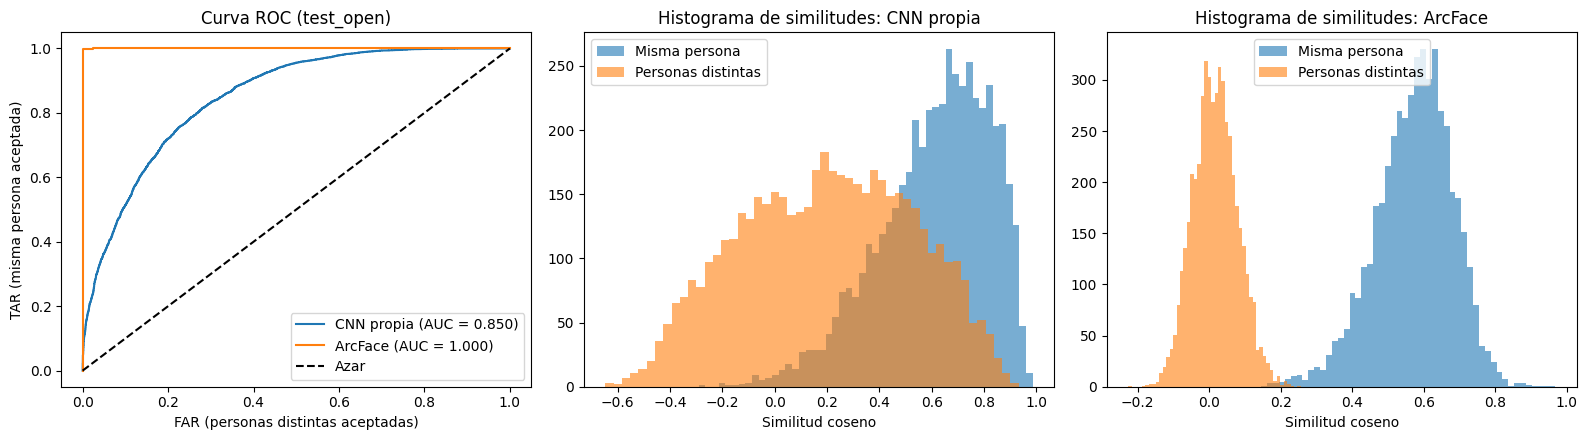

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(res_cnn[1], res_cnn[2], label=f"CNN propia (AUC = {res_cnn[3]:.3f})")
axes[0].plot(res_arc[1], res_arc[2], label=f"ArcFace (AUC = {res_arc[3]:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Azar")
axes[0].set_xlabel("FAR (personas distintas aceptadas)")
axes[0].set_ylabel("TAR (misma persona aceptada)")
axes[0].set_title("Curva ROC (test_open)")
axes[0].legend()

for ax, res, nombre in [(axes[1], res_cnn, "CNN propia"), (axes[2], res_arc, "ArcFace")]:
    sims = res[0]
    ax.hist(sims[misma_persona == 1], bins=50, alpha=0.6, label="Misma persona")
    ax.hist(sims[misma_persona == 0], bins=50, alpha=0.6, label="Personas distintas")
    ax.set_xlabel("Similitud coseno")
    ax.set_title(f"Histograma de similitudes: {nombre}")
    ax.legend()

plt.tight_layout()
plt.show()

3.3 c) Calibración del umbral


CNN propia: umbral = 0.890 | FAR = 0.0010 | FRR = 0.941
ArcFace: umbral = 0.230 | FAR = 0.0006 | FRR = 0.002


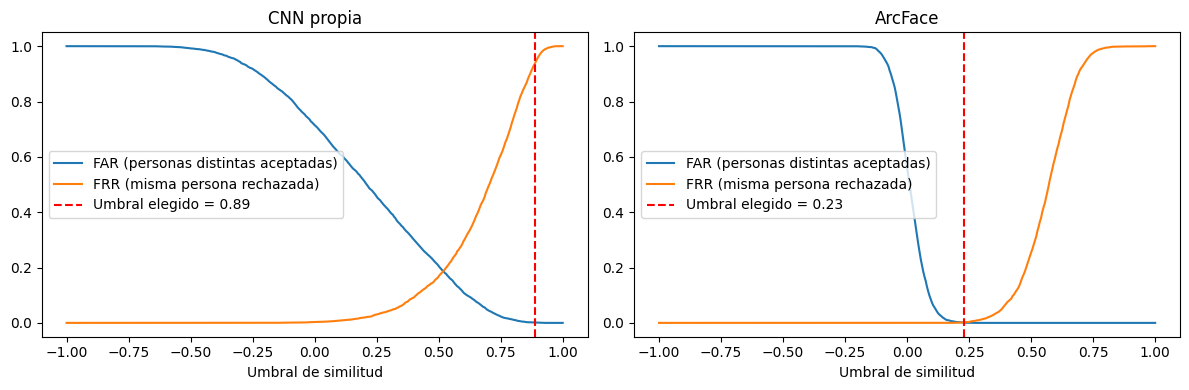

In [12]:
val = eval_df[eval_df["split"] == "val"]
pares_val, misma_val = generar_pares(val, 5000)

umbrales = np.linspace(-1, 1, 401)
FAR_OBJETIVO = 1e-3
umbral_elegido = {}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, emb, nombre in [(axes[0], emb_cnn, "CNN propia"), (axes[1], emb_arc, "ArcFace")]:
    sims = (emb[pares_val[:, 0]] * emb[pares_val[:, 1]]).sum(axis=1)
    far = np.array([(sims[misma_val == 0] >= u).mean() for u in umbrales])
    frr = np.array([(sims[misma_val == 1] < u).mean() for u in umbrales])

    u = umbrales[np.argmax(far <= FAR_OBJETIVO)]
    umbral_elegido[nombre] = u
    print(f"{nombre}: umbral = {u:.3f} | FAR = {far[umbrales == u][0]:.4f} | FRR = {frr[umbrales == u][0]:.3f}")

    ax.plot(umbrales, far, label="FAR (personas distintas aceptadas)")
    ax.plot(umbrales, frr, label="FRR (misma persona rechazada)")
    ax.axvline(u, color="red", linestyle="--", label=f"Umbral elegido = {u:.2f}")
    ax.set_xlabel("Umbral de similitud")
    ax.set_title(nombre)
    ax.legend()

plt.tight_layout()
plt.show()

ArcFace (umbral 0,23): cuando el FAR (azul) ya bajó a casi 0, el FRR (naranja) todavía no empezó a subir. Hay un margen amplio, aproximadamente entre 0,2 y 0,3, donde los dos errores son prácticamente 0. Con 0,23, la app casi no confunde personas y casi no rechaza a la persona correcta.

CNN (umbral 0,89): las curvas se cruzan en el medio (~0,5, que es el EER). Para llevar el FAR a 1 en 1.000 hay que subir el umbral a 0,89, y ahí el FRR ya está cerca del 95%: la app rechazaría como unknown a casi todas las personas registradas. Es el compromiso imposible que ya anticipaba el histograma.


3.3 b) Identificación: ¿quién es?


In [13]:
from sklearn.metrics import precision_recall_fscore_support

N_GALERIA = 3


def evaluar_identificacion(emb, umbral):
    rng_id = np.random.default_rng(SEED)
    conocidas = eval_df[eval_df["split"] == "test_closed"]
    galeria_idx, probes_idx = [], []
    for persona, idx in conocidas.groupby("identidad").groups.items():
        idx = rng_id.permutation(np.array(idx))
        galeria_idx += list(idx[:N_GALERIA])
        probes_idx += list(idx[N_GALERIA:])
    desconocidas_idx = list(eval_df.index[eval_df["split"] == "test_open"])

    nombres_gal = eval_df.loc[galeria_idx, "identidad"].to_numpy()
    personas = np.array(sorted(set(nombres_gal)))

    def puntajes(idx):
        sims = emb[idx] @ emb[galeria_idx].T
        return np.stack([sims[:, nombres_gal == p].max(axis=1) for p in personas], axis=1)

    p_conocidas = puntajes(probes_idx)
    reales = eval_df.loc[probes_idx, "identidad"].to_numpy()
    orden = np.argsort(-p_conocidas, axis=1)
    top1 = personas[orden[:, 0]]
    top5 = personas[orden[:, :5]]

    pred = np.where(p_conocidas.max(axis=1) >= umbral, top1, "unknown")
    precision, recall, f1, _ = precision_recall_fscore_support(
        reales, pred, labels=personas, average="macro", zero_division=0)

    p_desc = puntajes(desconocidas_idx)

    resultados = {
        "Top-1 accuracy": (top1 == reales).mean(),
        "Top-5 accuracy": np.mean([r in fila for r, fila in zip(reales, top5)]),
        "Precision (macro)": precision,
        "Recall (macro)": recall,
        "F1 (macro)": f1,
        "Desconocidos rechazados": (p_desc.max(axis=1) < umbral).mean(),
    }
    return resultados, reales, pred


res_id_cnn, reales_cnn, pred_cnn = evaluar_identificacion(emb_cnn, umbral_elegido["CNN propia"])
res_id_arc, reales_arc, pred_arc = evaluar_identificacion(emb_arc, umbral_elegido["ArcFace"])

pd.DataFrame({"CNN propia": res_id_cnn, "ArcFace": res_id_arc}).round(3)

,CNN propia,ArcFace
Top-1 accuracy,0.433,0.999
Top-5 accuracy,0.771,0.999
Precision (macro),0.550,1.000
Recall (macro),0.136,0.999
F1 (macro),0.197,1.000
Desconocidos rechazados,0.864,0.810


Es casi exactamente el 19% que se coló. El umbral calibrado para pares no sirve tal cual para identificación: cuantas más personas registradas tiene la app, más fácil es que un desconocido “se parezca” a alguna. Este hallazgo es de los que suman en la defensa.


La solución es calibrar el umbral simulando la identificación en validación: registramos a algunas personas de val y dejamos otras afuera como desconocidas. Elegimos el umbral más bajo que rechace al 99% de los desconocidos.


CNN propia: umbral = 0.925 | desconocidos rechazados = 0.990 | conocidos bien identificados = 0.030
ArcFace: umbral = 0.330 | desconocidos rechazados = 0.990 | conocidos bien identificados = 0.997


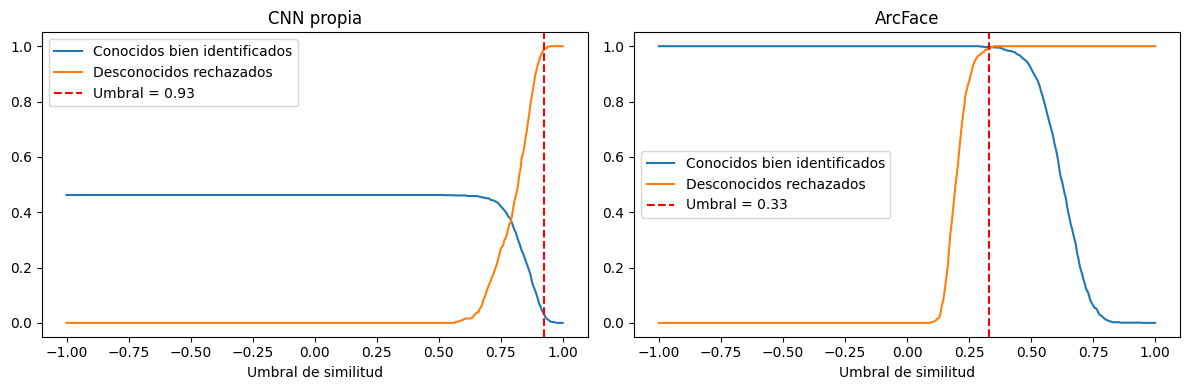

In [14]:
def barrido_identificacion(emb, umbrales):
    rng_v = np.random.default_rng(SEED)
    val = eval_df[eval_df["split"] == "val"]
    no_registradas = set(rng_v.choice(sorted(val["identidad"].unique()), size=20, replace=False))

    galeria_idx, probes_idx, desc_idx = [], [], []
    for persona, idx in val.groupby("identidad").groups.items():
        idx = rng_v.permutation(np.array(idx))
        if persona in no_registradas:
            desc_idx += list(idx)
        else:
            galeria_idx += list(idx[:N_GALERIA])
            probes_idx += list(idx[N_GALERIA:])

    nombres_gal = eval_df.loc[galeria_idx, "identidad"].to_numpy()
    reales = eval_df.loc[probes_idx, "identidad"].to_numpy()

    sims_conocidas = emb[probes_idx] @ emb[galeria_idx].T
    mejor_conocidas = sims_conocidas.max(axis=1)
    top1 = nombres_gal[sims_conocidas.argmax(axis=1)]
    mejor_desc = (emb[desc_idx] @ emb[galeria_idx].T).max(axis=1)

    identificados = np.array([((mejor_conocidas >= u) & (top1 == reales)).mean() for u in umbrales])
    rechazados = np.array([(mejor_desc < u).mean() for u in umbrales])
    return identificados, rechazados


RECHAZO_OBJETIVO = 0.99

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, emb, nombre in [(axes[0], emb_cnn, "CNN propia"), (axes[1], emb_arc, "ArcFace")]:
    identificados, rechazados = barrido_identificacion(emb, umbrales)
    i = np.argmax(rechazados >= RECHAZO_OBJETIVO)
    umbral_elegido[nombre] = umbrales[i]
    print(f"{nombre}: umbral = {umbrales[i]:.3f} | desconocidos rechazados = {rechazados[i]:.3f} "
          f"| conocidos bien identificados = {identificados[i]:.3f}")

    ax.plot(umbrales, identificados, label="Conocidos bien identificados")
    ax.plot(umbrales, rechazados, label="Desconocidos rechazados")
    ax.axvline(umbrales[i], color="red", linestyle="--", label=f"Umbral = {umbrales[i]:.2f}")
    ax.set_xlabel("Umbral de similitud")
    ax.set_title(nombre)
    ax.legend()

plt.tight_layout()
plt.show()

**Recalibración para identificación.** Al evaluar la identificación con el umbral calibrado sobre pares (0,23), ArcFace rechazaba solo el 81% de las personas no registradas, aunque ese umbral aceptaba apenas 1 de cada 1.000 pares de personas distintas. La razón es que en la identificación cada cara desconocida se compara con todas las fotos de la galería (en nuestro caso 255) y se queda con la más parecida. Si cada comparación tiene una probabilidad de 0,001 de superar el umbral, la probabilidad de que alguna de las 255 lo supere es 1 − (1 − 0,001)²⁵⁵ ≈ 22%, que coincide con lo que observamos. Es decir: cuantas más personas registradas tiene la app, más fácil es que un desconocido se parezca a alguna.

Por eso volvimos a calibrar el umbral simulando la identificación en validación: registramos 3 fotos de 65 personas y dejamos otras 20 personas sin registrar, como desconocidas. Elegimos el umbral más bajo que rechaza al 99% de los desconocidos.

- **ArcFace: umbral 0,33.** Rechaza al 99% de los desconocidos e identifica correctamente al 99,7% de las personas registradas. Las dos curvas se mantienen cerca de 1 en un rango amplio (aproximadamente entre 0,3 y 0,4), así que el resultado no es muy sensible al valor exacto. **Este es el umbral que configuramos en la app** (`SIMILARITY_THRESHOLD=0.33`).
- **CNN propia: umbral 0,925.** Para rechazar al 99% de los desconocidos, solo identifica bien al 3% de los registrados. Incluso sin umbral, identifica correctamente a menos de la mitad. No hay ningún umbral que la haga usable.


In [15]:
res_id_cnn, reales_cnn, pred_cnn = evaluar_identificacion(emb_cnn, umbral_elegido["CNN propia"])
res_id_arc, reales_arc, pred_arc = evaluar_identificacion(emb_arc, umbral_elegido["ArcFace"])

pd.DataFrame({"CNN propia": res_id_cnn, "ArcFace": res_id_arc}).round(3)

,CNN propia,ArcFace
Top-1 accuracy,0.433,0.999
Top-5 accuracy,0.771,0.999
Precision (macro),0.440,1.000
Recall (macro),0.051,0.993
F1 (macro),0.084,0.996
Desconocidos rechazados,0.975,0.999


In [16]:
for nombre, emb in [("CNN propia", emb_cnn), ("ArcFace", emb_arc)]:
    _, reales, pred = evaluar_identificacion(emb, -2)
    errores = pd.DataFrame({"real": reales, "predicho": pred})
    errores = errores[errores["real"] != errores["predicho"]]
    print(f"\n{nombre}: {len(errores)} errores de {len(reales)} consultas")
    print(errores.value_counts().head(10))


CNN propia: 982 errores de 1731 consultas
real                predicho          
amber heard         scarlett johansson    9
Andy Samberg        Mark Zuckerberg       8
Sophie Turner       scarlett johansson    7
Alexandra Daddario  Katharine Mcphee      6
Andy Samberg        Tom Holland           6
Eliza Taylor        Avril Lavigne         6
Logan Lerman        grant gustin          6
Tom Holland         Andy Samberg          6
                    Mark Zuckerberg       6
Anne Hathaway       Tuppence Middleton    5
Name: count, dtype: int64

ArcFace: 1 errores de 1731 consultas
real         predicho   
Ben Affleck  Johnny Depp    1
Name: count, dtype: int64


**Identidades más confundidas.** Con 85 personas la matriz de confusión no se puede leer, así que listamos los pares (persona real, persona predicha) más frecuentes, usando la predicción top-1 sin umbral.

La CNN se equivoca en 982 de 1.731 consultas. Las confusiones más frecuentes son entre personas del mismo género, de edad parecida y con rasgos generales similares: por ejemplo, entre varias actrices de pelo claro (Amber Heard, Sophie Turner, Scarlett Johansson) o entre varios hombres jóvenes de pelo oscuro (Andy Samberg, Tom Holland, Mark Zuckerberg). Esto sugiere que la CNN aprendió sobre todo rasgos generales de la cara, el pelo o la iluminación, y no los detalles finos que distinguen a una persona de otra parecida.

ArcFace se equivoca en una sola consulta de 1.731.


3.3 e) Análisis de errores con imágenes


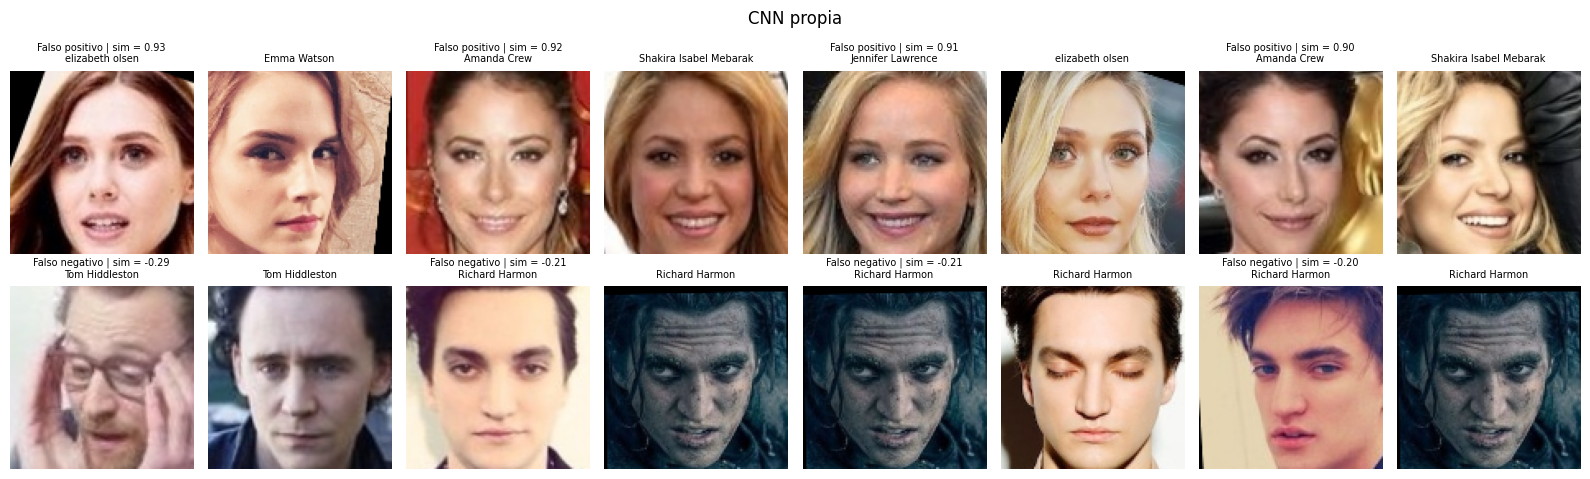

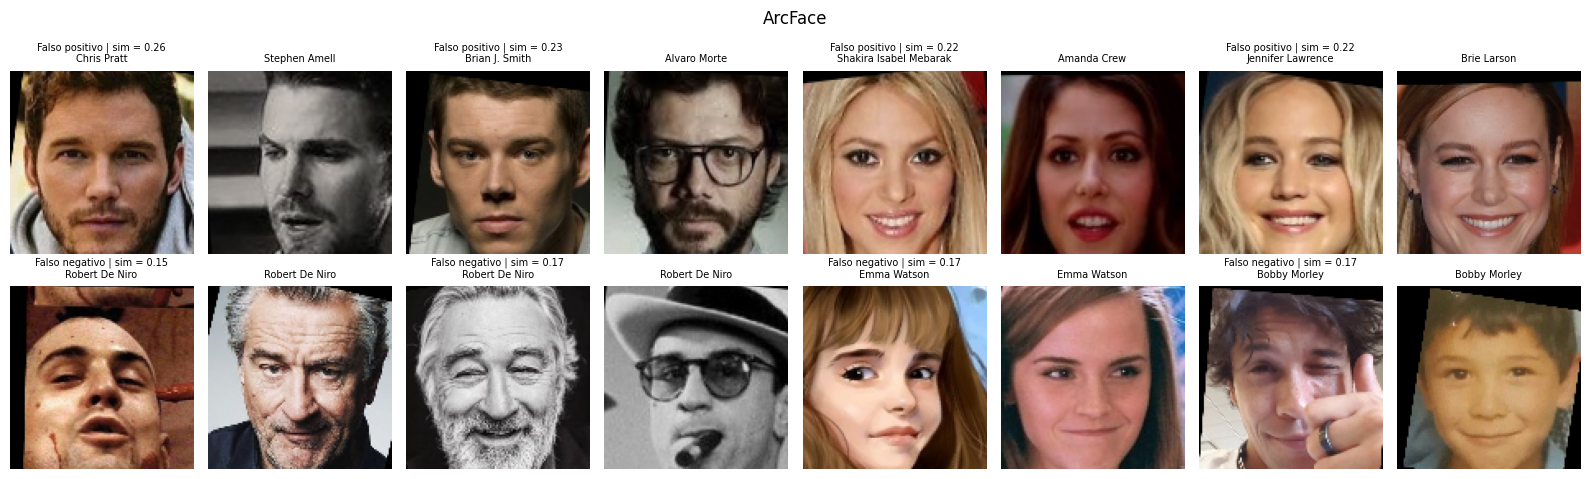

In [17]:
def mostrar_errores(res, nombre, n=4):
    sims = res[0]
    negativos = np.where(misma_persona == 0)[0]
    positivos = np.where(misma_persona == 1)[0]
    falsos_pos = negativos[np.argsort(-sims[negativos])[:n]]
    falsos_neg = positivos[np.argsort(sims[positivos])[:n]]

    fig, axes = plt.subplots(2, 2 * n, figsize=(16, 5))
    for fila, (casos, tipo) in enumerate([(falsos_pos, "Falso positivo"), (falsos_neg, "Falso negativo")]):
        for j, k in enumerate(casos):
            for m, idx in enumerate(pares[k]):
                ax = axes[fila, 2 * j + m]
                ax.imshow(cv2.cvtColor(cv2.imread(eval_df.loc[idx, "path_alineada"]), cv2.COLOR_BGR2RGB))
                titulo = eval_df.loc[idx, "identidad"]
                if m == 0:
                    titulo = f"{tipo} | sim = {sims[k]:.2f}\n{titulo}"
                ax.set_title(titulo, fontsize=7)
                ax.axis("off")
    fig.suptitle(nombre)
    plt.tight_layout()
    plt.show()


mostrar_errores(res_cnn, "CNN propia")
mostrar_errores(res_arc, "ArcFace")

3.3 d) Clustering de los embeddings


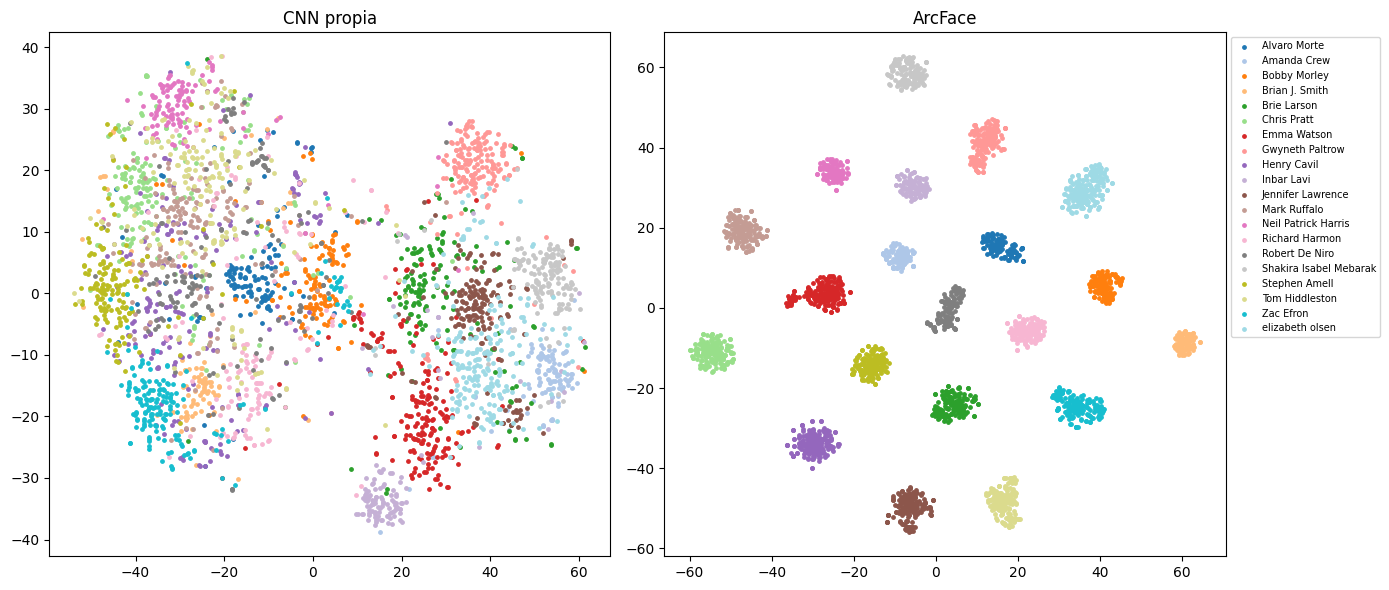

,CNN propia,ArcFace
Silhouette,0.041,0.514
ARI,0.340,0.963
NMI,0.526,0.986


In [18]:
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

es_open = (eval_df["split"] == "test_open").to_numpy()
nombres_open = eval_df.loc[es_open, "identidad"].to_numpy()
personas_open = sorted(set(nombres_open))
colores = plt.cm.tab20(np.linspace(0, 1, len(personas_open)))

metricas_clu = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, emb, nombre in [(axes[0], emb_cnn, "CNN propia"), (axes[1], emb_arc, "ArcFace")]:
    e = emb[es_open]
    clusters = KMeans(n_clusters=len(personas_open), n_init=10, random_state=SEED).fit_predict(e)
    metricas_clu[nombre] = {
        "Silhouette": silhouette_score(e, nombres_open, metric="cosine"),
        "ARI": adjusted_rand_score(nombres_open, clusters),
        "NMI": normalized_mutual_info_score(nombres_open, clusters),
    }

    puntos = TSNE(n_components=2, metric="cosine", random_state=SEED).fit_transform(e)
    for i, p in enumerate(personas_open):
        sel = nombres_open == p
        ax.scatter(puntos[sel, 0], puntos[sel, 1], s=6, color=colores[i], label=p)
    ax.set_title(nombre)

axes[1].legend(fontsize=7, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

pd.DataFrame(metricas_clu).round(3)

ArcFace: 20 grupos compactos y bien separados, uno por persona, aunque son personas que nunca vio. Las métricas son casi iguales a las del clustering de la Parte 1 (ARI 0,974).

CNN: las personas aparecen mezcladas. Algunas forman grupitos reconocibles (por ejemplo, el rosa arriba a la derecha, el rojo y el lila abajo), pero la mayoría se superponen. El silhouette de 0,04 es prácticamente 0: en promedio, cada cara está casi igual de cerca de su propia persona que de otra.

Algo que llama la atención: en la CNN los puntos se reparten en dos grandes zonas, izquierda y derecha. Viendo que en las confusiones la CNN mezclaba sobre todo personas del mismo género, es probable que esas dos zonas separen principalmente por género. Es una hipótesis: para confirmarla habría que mirar qué personas caen de cada lado.


3.3 f) Costo computacional


In [19]:
import os
import time
import onnx
import onnxruntime as ort

onnx_arc = onnx.load("models/w600k_r50.onnx")
params_arc = sum(int(np.prod(t.dims)) for t in onnx_arc.graph.initializer)
params_cnn = sum(p.numel() for p in modelo.parameters())

sesion_arc = ort.InferenceSession("models/w600k_r50.onnx")
nombre_entrada = sesion_arc.get_inputs()[0].name

cara, _ = CarasDataset(eval_df)[0]
cara = cara.unsqueeze(0)


def medir_ms(funcion, repeticiones=50):
    funcion()
    inicio = time.time()
    for _ in range(repeticiones):
        funcion()
    return (time.time() - inicio) / repeticiones * 1000


modelo.eval()
with torch.no_grad():
    ms_cnn = medir_ms(lambda: modelo.obtener_embedding(cara))
ms_arc = medir_ms(lambda: sesion_arc.run(None, {nombre_entrada: cara.numpy()}))

costo = pd.DataFrame({
    "CNN propia": [params_cnn, os.path.getsize("models/cnn_caras_final.pth") / 1e6, ms_cnn, emb_cnn.shape[1]],
    "ArcFace": [params_arc, os.path.getsize("models/w600k_r50.onnx") / 1e6, ms_arc, emb_arc.shape[1]],
}, index=["Parámetros", "Tamaño (MB)", "Tiempo por cara en CPU (ms)", "Dimensión del embedding"])
costo.round(1)

,CNN propia,ArcFace
Parámetros,433237.0,43590976.0
Tamaño (MB),1.7,174.4
Tiempo por cara en CPU (ms),9.2,104.3
Dimensión del embedding,128.0,512.0


In [20]:
tabla_final = pd.concat([
    tabla_verif,
    pd.DataFrame({"CNN propia": res_id_cnn, "ArcFace": res_id_arc}),
    pd.DataFrame(metricas_clu),
    costo,
    pd.DataFrame({"CNN propia": [umbral_elegido["CNN propia"]], "ArcFace": [umbral_elegido["ArcFace"]]},
                 index=["Umbral elegido"]),
]).round(3)
tabla_final

,CNN propia,ArcFace
AUC,0.850,1.000000e+00
EER,0.236,2.000000e-03
TAR @ FAR=1e-2,0.162,1.000000e+00
TAR @ FAR=1e-3,0.051,9.970000e-01
Top-1 accuracy,0.433,9.990000e-01
Top-5 accuracy,0.771,9.990000e-01
Precision (macro),0.440,1.000000e+00
Recall (macro),0.051,9.930000e-01
F1 (macro),0.084,9.960000e-01
Desconocidos rechazados,0.975,9.990000e-01


### Elección del modelo

**Elegimos ArcFace para la app.**

- **Desempeño:** es muy superior en todas las métricas. En verificación tiene un EER de 0,2% contra 23,6% de la CNN, y con el umbral calibrado identifica correctamente al 99,3% de las personas registradas y rechaza al 99,9% de las desconocidas. Con la CNN no existe ningún umbral que permita usarla: para rechazar a los desconocidos tiene que rechazar también a casi todos los registrados.
- **Costo:** es 100 veces más grande y unas 11 veces más lento que la CNN, pero 104 ms por cara en CPU es perfectamente aceptable para la app.
- **Licencia:** solo permite uso no comercial o de investigación. Para este trabajo está bien, pero no se podría usar en un producto comercial.
- **Integración:** ya viene en formato ONNX, usa el mismo detector y la misma alineación que usamos en todo el trabajo, e InsightFace ya está en el `requirements.txt` de la app.

### ¿Por qué la CNN rinde mucho menos?

1. **Datos:** la entrenamos con unas 9.500 imágenes de 85 personas. ArcFace fue entrenado con millones de imágenes de unas 600 mil personas. Con tan pocas identidades, la red no tiene suficientes ejemplos para aprender qué distingue a una persona de cualquier otra.
2. **Tamaño del modelo:** tiene 433 mil parámetros contra 43 millones de ArcFace. Una red tan chica tiene poca capacidad para representar detalles finos de la cara.
3. **Función de pérdida:** la entrenamos con cross-entropy para clasificar a las 85 personas. Esa loss solo busca que cada cara quede del lado correcto de la frontera entre clases, pero no obliga a que las caras de una misma persona queden juntas ni lejos de las de otras personas. ArcFace usa un margen angular que fuerza justamente eso, y por eso sus embeddings separan tan bien a personas nuevas.
4. **Entrenamiento incompleto:** por entrenar en CPU, hicimos 30 épocas (unas 2,5 horas) y el modelo todavía no había terminado de aprender.

En los resultados se ve el efecto: la CNN aprendió sobre todo rasgos generales, como el género, el color de pelo o la pose, y por eso confunde a personas parecidas en esos aspectos.

Para mejorarla, en orden de impacto esperado: entrenar con más identidades, usar una loss de metric learning (ArcFace o triplet loss) en lugar de clasificación, hacer fine-tuning de un backbone preentrenado (como ResNet18), y entrenar más épocas con GPU.

**Una aclaración sobre ArcFace:** es probable que varias de las celebridades de Pins estuvieran en sus datos de entrenamiento, así que sus resultados pueden estar inflados. Con caras de personas comunes, que es lo que va a recibir la app, probablemente rinda algo peor.

### Configuración para la app

| Variable               | Valor            |
| ---------------------- | ---------------- |
| `MODEL_NAME`           | `w600k_r50.onnx` |
| `DETECTOR_MODEL_NAME`  | `det_10g.onnx`   |
| `EMBEDDING_DIM`        | 512              |
| `FACE_SIZE`            | 112              |
| `SIMILARITY_METRIC`    | `cosine`         |
| `SIMILARITY_THRESHOLD` | 0.33             |

**Modelo:** como elegimos ArcFace, no hace falta exportar nada: ya viene en ONNX. Se descarga desde el release oficial de InsightFace: https://github.com/deepinsight/insightface/releases/download/v0.7/buffalo_l.zip (de ese zip se usan `w600k_r50.onnx` y `det_10g.onnx`).
